## Preprocessing NIfTI files: analogpus pipeline as for other dataset

In [8]:
import os
import numpy as np
import nibabel as nib
from PIL import Image, ImageFilter
from skimage import exposure

def load_nifti_image(path):
    """Load a NIfTI file and return a NumPy array of shape (H, W, D)."""
    img = nib.load(path)
    data = img.get_fdata(dtype=np.float32)
    return data

def preprocess_slice(
    slice_2d,
    resize_dim=128,
    filter_mode="none",
    apply_hist_eq=False
):
    """Normalize, (optional) CLAHE, filter, resize and return a PIL.Image."""
    # Normalize to [0,1]
    if slice_2d.max() > 0:
        slice_2d = slice_2d / slice_2d.max()

    # CLAHE
    if apply_hist_eq:
        slice_2d = exposure.equalize_adapthist(slice_2d, clip_limit=0.03)

    # Convert → PIL for filtering & resizing
    img = Image.fromarray((slice_2d * 255).astype(np.uint8))
    if filter_mode == "blur":
        img = img.filter(ImageFilter.BLUR)
    elif filter_mode == "sharpen":
        img = img.filter(ImageFilter.SHARPEN)

    img = img.resize((resize_dim, resize_dim), Image.BILINEAR)
    return img

def infer_modality(folder_name):
    """
    Given a folder name like 'BraTS-GLI-00769-000-t1c.nii',
    return one of: 't1','t1c','t2','flair' or None.
    """
    fn = folder_name.lower()
    if "-t1c" in fn:
        return "t1c"
    if "-t1n" in fn:
        return "t1"
    if "-t2w" in fn:
        return "t2"
    if "t2f" in fn:
        return "flair"
    return None

def preprocess_brats_dataset(
    src_root,
    dst_root,
    resize_dim=128,
    filter_mode="none",
    apply_hist_eq=False
):
    if not os.path.isdir(src_root):
        raise FileNotFoundError(f"Source not found: {src_root!r}")
    os.makedirs(dst_root, exist_ok=True)

    for subj in sorted(os.listdir(src_root)):
        subj_dir = os.path.join(src_root, subj)
        if not os.path.isdir(subj_dir):
            continue

        print(f"\nProcessing subject: {subj}")
        out_subj = os.path.join(dst_root, subj)
        os.makedirs(out_subj, exist_ok=True)

        # Look for modality‐named subfolders under subj_dir
        for entry in sorted(os.listdir(subj_dir)):
            entry_path = os.path.join(subj_dir, entry)
            if not os.path.isdir(entry_path):
                continue

            mod = infer_modality(entry)
            if mod is None:
                print(f"  • Skipping folder (unknown modality): {entry}")
                continue

            # Inside this modality folder, find the actual .nii files
            nii_files = [f for f in os.listdir(entry_path)
                         if f.lower().endswith((".nii", ".nii.gz"))]
            if not nii_files:
                print(f"  • No .nii files in {entry} → skipping.")
                continue

            # Prepare output for this modality
            out_mod = os.path.join(out_subj, mod)
            os.makedirs(out_mod, exist_ok=True)

            for nifti_fn in nii_files:
                nifti_path = os.path.join(entry_path, nifti_fn)
                try:
                    print(f"  ▶ Loading {mod} volume: {nifti_fn}")
                    vol = load_nifti_image(nifti_path)  # shape (H, W, D)
                except Exception as e:
                    print(f"    ✗ Failed to load {nifti_fn}: {e}")
                    continue

                # Process each axial slice
                n_slices = vol.shape[2]
                for z in range(n_slices):
                    slice2d = vol[:, :, z]
                    img = preprocess_slice(
                        slice2d,
                        resize_dim=resize_dim,
                        filter_mode=filter_mode,
                        apply_hist_eq=apply_hist_eq
                    )
                    out_name = f"{subj}_{mod}_slice{z:03d}.png"
                    img.save(os.path.join(out_mod, out_name))

                print(f"    ✓ Saved {n_slices} slices to {out_mod}")

if __name__ == "__main__":
    src_root = r"C:\Users\jxmra\Downloads\BratsGlioma\TestingData"
    dst_root = r"C:\Users\jxmra\Downloads\BraTS_preprocessed"

    print("Source exists? ", os.path.isdir(src_root))
    print("Output root:  ", dst_root)

    preprocess_brats_dataset(
        src_root=src_root,
        dst_root=dst_root,
        resize_dim=128,
        filter_mode="blur",
        apply_hist_eq=True
    )


Source exists?  True
Output root:   C:\Users\jxmra\Downloads\BraTS_preprocessed

Processing subject: BraTS-GLI-00000-000
  ▶ Loading t1c volume: 00000057_brain_t1ce.nii
    ✓ Saved 155 slices to C:\Users\jxmra\Downloads\BraTS_preprocessed\BraTS-GLI-00000-000\t1c
  ▶ Loading t1 volume: 00000057_brain_t1.nii
    ✓ Saved 155 slices to C:\Users\jxmra\Downloads\BraTS_preprocessed\BraTS-GLI-00000-000\t1
  ▶ Loading flair volume: 00000057_brain_flair.nii
    ✓ Saved 155 slices to C:\Users\jxmra\Downloads\BraTS_preprocessed\BraTS-GLI-00000-000\flair
  ▶ Loading t2 volume: 00000057_brain_t2.nii
    ✓ Saved 155 slices to C:\Users\jxmra\Downloads\BraTS_preprocessed\BraTS-GLI-00000-000\t2

Processing subject: BraTS-GLI-00001-000
  ▶ Loading t1c volume: 00000096_brain_t1ce.nii
    ✓ Saved 155 slices to C:\Users\jxmra\Downloads\BraTS_preprocessed\BraTS-GLI-00001-000\t1c
  ▶ Loading t1 volume: 00000096_brain_t1.nii
    ✓ Saved 155 slices to C:\Users\jxmra\Downloads\BraTS_preprocessed\BraTS-GLI-00001-

KeyboardInterrupt: 

## Apllying augmentation techniques to files.

In [9]:
import os
import random
import numpy as np
from PIL import Image, ImageFilter, ImageEnhance
import cv2
import torchvision.transforms.functional as F

def make_motion_blur_kernel(k_size: int, angle: float = 0.0):
    """
    Create a motion-blur kernel of size k_sizexk_size at given angle.
    """
    # start with a horizontal line
    kernel = np.zeros((k_size, k_size), dtype=np.float32)
    kernel[int((k_size - 1) / 2), :] = np.ones(k_size, dtype=np.float32)
    # rotate kernel by angle
    M = cv2.getRotationMatrix2D((k_size/2 - 0.5, k_size/2 - 0.5), angle, 1)
    kernel = cv2.warpAffine(kernel, M, (k_size, k_size))
    # normalize
    kernel = kernel / kernel.sum()
    return kernel

def augment_image(
    img: Image.Image,
    rotate_deg=30,
    do_rotate=True,
    do_flip=True,
    do_brightness=True,
    brightness_range=(0.8,1.2),
    do_contrast=True,
    contrast_range=(0.8,1.2),
    do_gamma=True,
    gamma_range=(0.8,1.2),
    do_noise=True,
    noise_sigma=0.05,
    do_motion_blur=True,
    mb_kernel_size=7
) -> Image.Image:
    """
    Takes a PIL.Image (L or RGB) and returns an augmented PIL.Image.
    """
    # 1) Rotation
    if do_rotate:
        angle = random.uniform(-rotate_deg, rotate_deg)
        img = img.rotate(angle, resample=Image.BILINEAR, fillcolor=0)

    # 2) Flip
    if do_flip:
        if random.random() < 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
        if random.random() < 0.5:
            img = img.transpose(Image.FLIP_TOP_BOTTOM)

    # 3) Brightness
    if do_brightness:
        factor = random.uniform(*brightness_range)
        img = ImageEnhance.Brightness(img).enhance(factor)

    # 4) Contrast
    if do_contrast:
        factor = random.uniform(*contrast_range)
        img = ImageEnhance.Contrast(img).enhance(factor)

    # 5) Gamma
    if do_gamma:
        gamma = random.uniform(*gamma_range)
        img = F.adjust_gamma(img, gamma, gain=1.0)

    # 6) Gaussian noise
    if do_noise:
        arr = np.array(img).astype(np.float32) / 255.0
        noise = np.random.normal(0, noise_sigma, arr.shape)
        arr = np.clip(arr + noise, 0.0, 1.0)
        img = Image.fromarray((arr * 255).astype(np.uint8))

    # 7) Motion blur
    if do_motion_blur:
        angle = random.uniform(0, 360)
        kernel = make_motion_blur_kernel(mb_kernel_size, angle)
        arr = np.array(img)
        # if grayscale:
        if arr.ndim == 2:
            blurred = cv2.filter2D(arr, -1, kernel)
        else:
            # for RGB, blur each channel
            channels = [cv2.filter2D(arr[...,c], -1, kernel) for c in range(3)]
            blurred = np.stack(channels, axis=-1)
        img = Image.fromarray(np.uint8(np.clip(blurred, 0, 255)))

    return img

def bulk_augment_preprocessed(
    src_root: str,
    dst_root: str,
    copies_per_image: int = 2,
    **aug_kwargs
):
    """
    Walks src_root/<subject>/<modality>/*.jpg (or .png),
    applies augment_image() copies_per_image times,
    and saves to dst_root/<subject>/<modality>/ with suffix _aug<i>.
    """
    for subj in sorted(os.listdir(src_root)):
        subj_in = os.path.join(src_root, subj)
        if not os.path.isdir(subj_in):
            continue

        for mod in sorted(os.listdir(subj_in)):
            mod_in = os.path.join(subj_in, mod)
            if not os.path.isdir(mod_in):
                continue

            # prepare output
            mod_out = os.path.join(dst_root, subj, mod)
            os.makedirs(mod_out, exist_ok=True)

            for fname in sorted(os.listdir(mod_in)):
                if not fname.lower().endswith((".png", ".jpg", ".jpeg")):
                    continue

                path_in = os.path.join(mod_in, fname)
                try:
                    img = Image.open(path_in).convert("L")
                except Exception as e:
                    print(f"Failed to open {path_in}: {e}")
                    continue

                base, ext = os.path.splitext(fname)
                # save original (optional): uncomment if desired
                # img.save(os.path.join(mod_out, f"{base}.png"))

                for i in range(copies_per_image):
                    aug = augment_image(img, **aug_kwargs)
                    out_name = f"{base}_aug{i+1}.jpg"
                    aug.save(
                        os.path.join(mod_out, out_name),
                        format="JPEG",
                        quality=95
                    )
                print(f"✔ {subj}/{mod}/{fname} → {copies_per_image} augmentations saved")

if __name__ == "__main__":
    # Example usage
    SRC = r"C:\Users\jxmra\Downloads\BraTS_preprocessed"
    DST = r"C:\Users\jxmra\Downloads\BraTS_augmented"

    bulk_augment_preprocessed(
        src_root=SRC,
        dst_root=DST,
        copies_per_image=3,
        rotate_deg=30,
        do_rotate=True,
        do_flip=True,
        do_brightness=True,
        brightness_range=(0.8,1.2),
        do_contrast=True,
        contrast_range=(0.8,1.2),
        do_gamma=True,
        gamma_range=(0.8,1.2),
        do_noise=True,
        noise_sigma=0.05,
        do_motion_blur=True,
        mb_kernel_size=7
    )


✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice000.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice001.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice002.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice003.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice004.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice005.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice006.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice007.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice008.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice009.png → 3 augmentations saved
✔ BraTS-GLI-00000-000/flair/BraTS-GLI-00000-000_flair_slice010.png → 3 augmentations saved

KeyboardInterrupt: 

## Boilerplate for experiments

In [ ]:
import os
import random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms as transforms
from torchvision import models
from PIL import Image
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
import pandas as pd

# ----------------------------------------
# Dataset class
# ----------------------------------------
class BrainTumorDataset(Dataset):
    def __init__(self, root_dir, modalities=['t1'], transform=None):
        """
        root_dir/
          subject1/
            t1/*.jpg
            t1c/*.jpg
            ...
        """
        self.samples = []
        self.transform = transform
        for subj in sorted(os.listdir(root_dir)):
            subj_dir = os.path.join(root_dir, subj)
            if not os.path.isdir(subj_dir):
                continue
            for mod in modalities:
                mod_dir = os.path.join(subj_dir, mod)
                if not os.path.isdir(mod_dir):
                    continue
                for fname in sorted(os.listdir(mod_dir)):
                    if fname.lower().endswith(('.png','.jpg','.jpeg')):
                        path = os.path.join(mod_dir, fname)
                        # label extraction for Nickparvar: assume folder name or a CSV mapping
                        label = self._infer_label(subj)
                        self.samples.append((path, label))

    def _infer_label(self, subject):
        # TODO: implement label lookup, e.g. from a CSV mapping for Nickparvar dataset
        # return int label [0..3]
        raise NotImplementedError

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

# ----------------------------------------
# Transforms for RQ1, RQ2, RQ3
# ----------------------------------------
def get_transforms(purpose='none'):
    base = [transforms.Resize((224,224)), transforms.ToTensor()]
    if purpose == 'rq1_aug':
        aug = [
            transforms.RandomRotation(30),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
        ]
        return transforms.Compose(aug + base)
    elif purpose == 'rq2_train':
        return transforms.Compose(base)
    elif purpose == 'rq2_test_perturbed':
        # same as basic, but add Gaussian noise and blur in Tensor space
        return transforms.Compose(base + [
            transforms.Lambda(lambda x: x + torch.randn_like(x)*0.05),
            transforms.Lambda(lambda x: transforms.functional.gaussian_blur(x, kernel_size=5)),
        ])
    elif purpose == 'rq3_aug':
        aug = [
            transforms.RandomRotation(30),
            transforms.RandomResizedCrop(224, scale=(0.8,1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
            transforms.Lambda(lambda x: x + torch.randn_like(x)*0.05),
        ]
        return transforms.Compose(aug + base)
    else:
        return transforms.Compose(base)

# ----------------------------------------
# Model: Transfer Learning (ResNet18)
# ----------------------------------------
def get_model(num_classes=4, device='cuda'):
    model = models.resnet18(pretrained=True)
    # replace final layer
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model.to(device)

# ----------------------------------------
# Training and evaluation
# ----------------------------------------
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())
    acc = accuracy_score(all_labels, all_preds)
    return running_loss/len(loader.dataset), acc


def eval_model(model, loader, device):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)[:,1].cpu().numpy()
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
            all_probs.extend(probs)
    acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro')
    try:
        auc = roc_auc_score(all_labels, all_probs, multi_class='ovo')
    except:
        auc = None
    return {'accuracy':acc, 'precision':precision, 'recall':recall, 'f1':f1, 'auc':auc}

# ----------------------------------------
# Experiment RQ1: k-fold on Nickparvar
# ----------------------------------------
def run_rq1(nick_root, k=5, num_epochs=10, batch_size=32, device='cuda'):
    transform_no = get_transforms('none')
    transform_yes = get_transforms('rq1_aug')

    ds = BrainTumorDataset(nick_root, transform=None)  # placeholder
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    results = []

    for fold, (train_idx, test_idx) in enumerate(kf.split(ds)):
        # datasets
        ds_train = Subset(ds, train_idx)
        ds_test = Subset(ds, test_idx)
        ds_train.dataset.transform = transform_yes
        ds_test.dataset.transform = transform_no

        loader_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True)
        loader_test = DataLoader(ds_test, batch_size=batch_size)

        model = get_model(device=device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=1e-4)

        # train
        for epoch in range(num_epochs):
            loss, acc = train_one_epoch(model, loader_train, criterion, optimizer, device)
            print(f"RQ1 Fold {fold+1} Epoch {epoch+1}/{num_epochs} loss={loss:.4f} acc={acc:.4f}")

        # eval
        metrics = eval_model(model, loader_test, device)
        metrics['fold'] = fold+1
        results.append(metrics)
        print(f"RQ1 Fold {fold+1} results: {metrics}")

    return pd.DataFrame(results)

# ----------------------------------------
# Experiment RQ2: robustness to perturbations
# ----------------------------------------
def run_rq2(nick_root, num_epochs=10, batch_size=32, device='cuda'):
    # train on clean
    ds_train = BrainTumorDataset(nick_root, transform=get_transforms('none'))
    loader_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True)

    # test on clean
    ds_test = BrainTumorDataset(nick_root, transform=get_transforms('none'))
    loader_clean = DataLoader(ds_test, batch_size=batch_size)

    # test on perturbed
    ds_testp = BrainTumorDataset(nick_root, transform=get_transforms('rq2_test_perturbed'))
    loader_pert = DataLoader(ds_testp, batch_size=batch_size)

    model = get_model(device=device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    for epoch in range(num_epochs):
        loss, acc = train_one_epoch(model, loader_train, criterion, optimizer, device)
        print(f"RQ2 Epoch {epoch+1}/{num_epochs} loss={loss:.4f} acc={acc:.4f}")

    clean_met = eval_model(model, loader_clean, device)
    pert_met = eval_model(model, loader_pert, device)

    drop = clean_met['accuracy'] - pert_met['accuracy']
    print(f"RQ2 Clean acc={clean_met['accuracy']:.4f}, Perturbed acc={pert_met['accuracy']:.4f}, Drop={drop:.4f}")

    return {'clean':clean_met, 'perturbed':pert_met, 'drop':drop}

# ----------------------------------------
# Experiment RQ3: generalization to BRATS
# ----------------------------------------
def run_rq3(nick_root, brats_root, num_epochs=10, batch_size=32, device='cuda'):
    # train on Nick with advanced augmentation
    ds_train = BrainTumorDataset(nick_root, transform=get_transforms('rq3_aug'))
    loader_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True)

    # test on BRATS
    ds_brats = BrainTumorDataset(brats_root, transform=get_transforms('none'))
    loader_brats = DataLoader(ds_brats, batch_size=batch_size)

    model = get_model(device=device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    for epoch in range(num_epochs):
        loss, acc = train_one_epoch(model, loader_train, criterion, optimizer, device)
        print(f"RQ3 Epoch {epoch+1}/{num_epochs} loss={loss:.4f} acc={acc:.4f}")

    brats_met = eval_model(model, loader_brats, device)

    # If BRATS metadata on scanner type is available, one could split here per-scanner
    print(f"RQ3 BRATS generalization results: {brats_met}")
    return brats_met

# ----------------------------------------
# Main
# ----------------------------------------
if __name__ == '__main__':
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    nick_root = r"/path/to/Nickparvar"  # update
    brats_root = r"/path/to/BraTS_preprocessed"  # update

    # RQ1
    df_rq1 = run_rq1(nick_root, k=5, num_epochs=10, batch_size=32, device=device)
    df_rq1.to_csv('rq1_results.csv', index=False)

    # RQ2
    res_rq2 = run_rq2(nick_root, num_epochs=10, batch_size=32, device=device)
    pd.DataFrame([res_rq2['clean'], res_rq2['perturbed']]).to_csv('rq2_results.csv', index=False)

    # RQ3
    res_rq3 = run_rq3(nick_root, brats_root, num_epochs=10, batch_size=32, device=device)
    pd.Series(res_rq3).to_csv('rq3_results.csv')


## Code to view niftii files

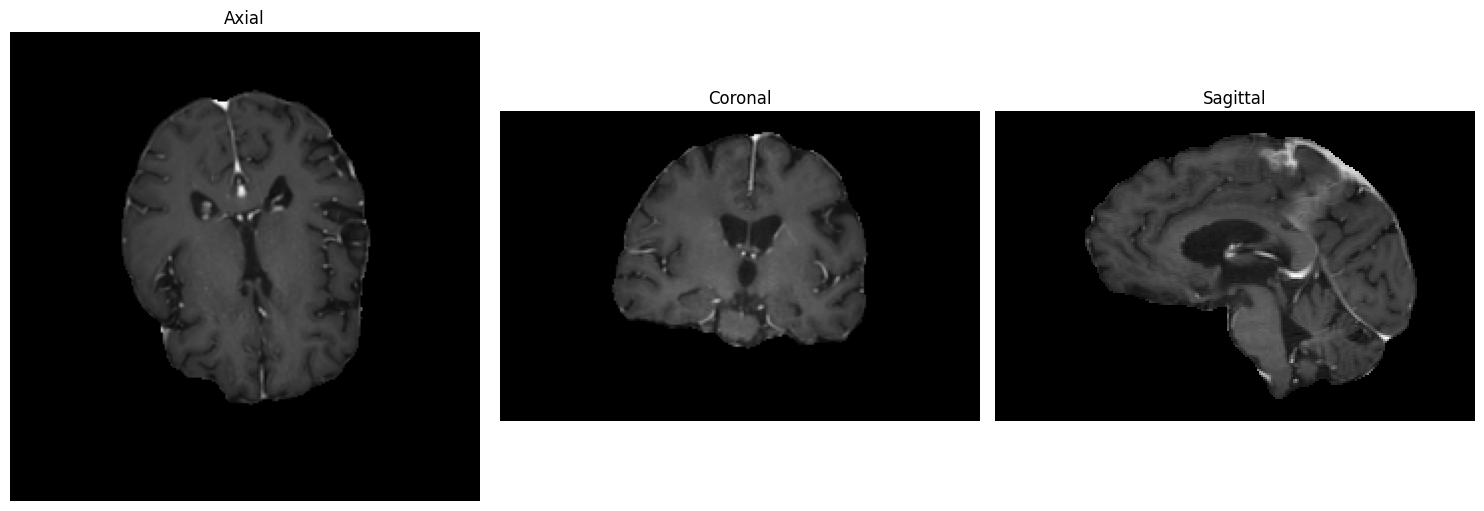

In [14]:
import os
import nibabel as nib
import matplotlib.pyplot as plt

# Function to display 3 orthogonal views (axial, coronal, sagittal)
def show_slices(slices, titles=None):
    fig, axes = plt.subplots(1, len(slices), figsize=(15, 5))
    for i, slice in enumerate(slices):
        ax = axes[i]
        ax.imshow(slice.T, cmap='gray', origin='lower')
        if titles:
            ax.set_title(titles[i])
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Load and display a single NIfTI volume

def view_nifti_volume(filepath):
    """
    Load a .nii or .nii.gz file and display the middle slices in all three planes.
    """
    if not os.path.isfile(filepath):
        raise FileNotFoundError(f"File not found: {filepath}")

    # Load the image
    img = nib.load(filepath)
    data = img.get_fdata()

    # Compute middle indices
    x_mid = data.shape[0] // 2
    y_mid = data.shape[1] // 2
    z_mid = data.shape[2] // 2

    # Extract slices
    axial = data[:, :, z_mid]
    coronal = data[:, y_mid, :]
    sagittal = data[x_mid, :, :]

    # Show them
    show_slices([axial, coronal, sagittal], titles=['Axial', 'Coronal', 'Sagittal'])

# Example usage
if __name__ == '__main__':
    # Replace with your path to a .nii file
    filepath = r"C:\Users\jxmra\Downloads\BratsGlioma\TestingData\BraTS-GLI-00769-000\BraTS-GLI-00769-000-t1c.nii\00000348_brain_t1ce.nii"
    view_nifti_volume(filepath)



## EDA of BRATS (without validation/training split)

                                                 filepath            shape  \
count                                                1192             1192   
unique                                               1192                1   
top     C:\Users\jxmra\Downloads\BratsGlioma\TestingDa...  (240, 240, 155)   
freq                                                    1             1192   
mean                                                  NaN              NaN   
std                                                   NaN              NaN   
min                                                   NaN              NaN   
25%                                                   NaN              NaN   
50%                                                   NaN              NaN   
75%                                                   NaN              NaN   
max                                                   NaN              NaN   

          dtype       voxel_size  mean_intensity  median_intens

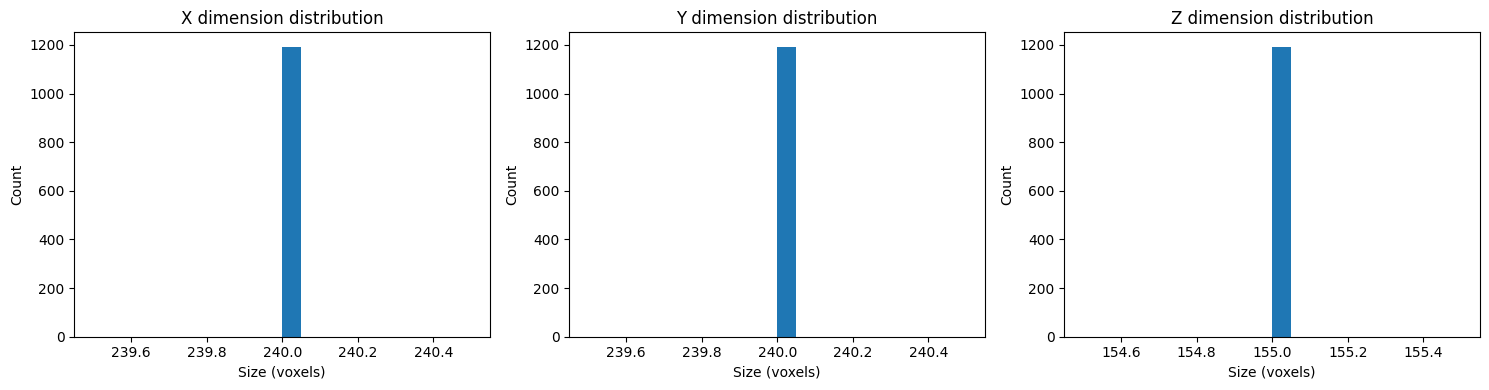

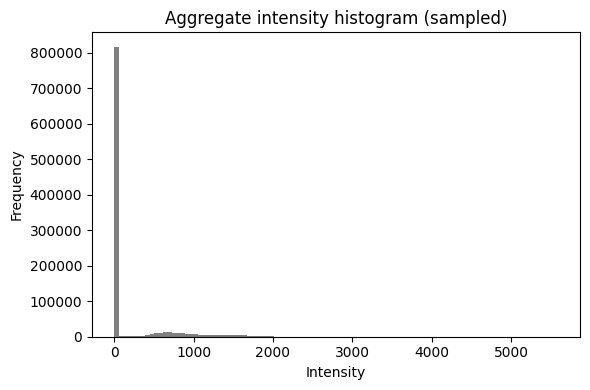

EDA complete. Results saved to C:\Users\jxmra\Downloads\eda_results


In [18]:
import os
import glob
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def gather_nifti_stats(root_dir):
    """
    Walk through root_dir, find .nii files ending with specific modality suffixes,
    and collect metadata and intensity stats. Returns a pandas DataFrame.
    """
    # Define the suffixes to include
    suffixes = ('brain_t1ce.nii', 'brain_t1.nii', 'brain_flair.nii', 'brain_t2.nii')
    records = []
    # Search for .nii (not .nii.gz unless needed)
    pattern = os.path.join(root_dir, '**', '*.nii')
    for filepath in glob.glob(pattern, recursive=True):
        fname = os.path.basename(filepath).lower()
        # Only include files matching our modality suffixes
        if not any(fname.endswith(suf) for suf in suffixes):
            continue
        try:
            img = nib.load(filepath)
            hdr = img.header
            data = img.get_fdata()

            shape = data.shape
            dtype = data.dtype
            zooms = hdr.get_zooms()  # voxel sizes

            # Basic intensity statistics
            flat = data.ravel()
            flat = flat[np.isfinite(flat)]
            if flat.size > 0:
                mean = float(np.mean(flat))
                median = float(np.median(flat))
                std = float(np.std(flat))
                vmin = float(np.min(flat))
                vmax = float(np.max(flat))
            else:
                mean = median = std = vmin = vmax = np.nan

            file_size = os.path.getsize(filepath)

            records.append({
                'filepath': filepath,
                'shape': shape,
                'dtype': str(dtype),
                'voxel_size': zooms,
                'mean_intensity': mean,
                'median_intensity': median,
                'std_intensity': std,
                'min_intensity': vmin,
                'max_intensity': vmax,
                'file_size_bytes': file_size
            })

        except Exception as e:
            print(f"Error processing {filepath}: {e}")

    df = pd.DataFrame.from_records(records)
    return df


def plot_shape_distribution(df, out_dir=None):
    """
    Plot histogram of volume shapes (number of slices in each axis).
    """
    if df.empty:
        print("No matching NIfTI files found for EDA.")
        return
    dims = np.stack(df['shape'].values)
    labels = ['X', 'Y', 'Z']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for i in range(3):
        axes[i].hist(dims[:, i], bins=20)
        axes[i].set_title(f"{labels[i]} dimension distribution")
        axes[i].set_xlabel('Size (voxels)')
        axes[i].set_ylabel('Count')
    plt.tight_layout()
    if out_dir:
        plt.savefig(os.path.join(out_dir, 'shape_distribution.png'))
    plt.show()


def plot_intensity_histograms(df, out_dir=None, bins=100):
    """
    Plot aggregate intensity histograms across volumes.
    """
    if df.empty:
        return
    fig, ax = plt.subplots(figsize=(6, 4))
    all_samples = []
    for path in df['filepath'].sample(min(len(df), 10), random_state=0):
        data = nib.load(path).get_fdata().ravel()
        data = data[np.isfinite(data)]
        if data.size > 100000:
            data = np.random.choice(data, 100000, replace=False)
        all_samples.append(data)
    if all_samples:
        concat = np.concatenate(all_samples)
        ax.hist(concat, bins=bins, color='gray')
        ax.set_title('Aggregate intensity histogram (sampled)')
        ax.set_xlabel('Intensity')
        ax.set_ylabel('Frequency')
        plt.tight_layout()
        if out_dir:
            plt.savefig(os.path.join(out_dir, 'intensity_histogram.png'))
        plt.show()


def run_eda(root_dir, output_dir=None):
    """
    Perform EDA: gather stats, save DataFrame, plot distributions.
    """
    df = gather_nifti_stats(root_dir)
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        df.to_csv(os.path.join(output_dir, 'nifti_summary.csv'), index=False)
    print(df.describe(include='all'))
    plot_shape_distribution(df, out_dir=output_dir)
    plot_intensity_histograms(df, out_dir=output_dir)
    return df


if __name__ == '__main__':
    # Example: replace with your actual paths
    src = r"C:\Users\jxmra\Downloads\BratsGlioma\TestingData"
    out = r"C:\Users\jxmra\Downloads\eda_results"
    df = run_eda(src, out)
    print("EDA complete. Results saved to", out)


In [19]:
print(df.head())

                                            filepath            shape  \
0  C:\Users\jxmra\Downloads\BratsGlioma\TestingDa...  (240, 240, 155)   
1  C:\Users\jxmra\Downloads\BratsGlioma\TestingDa...  (240, 240, 155)   
2  C:\Users\jxmra\Downloads\BratsGlioma\TestingDa...  (240, 240, 155)   
3  C:\Users\jxmra\Downloads\BratsGlioma\TestingDa...  (240, 240, 155)   
4  C:\Users\jxmra\Downloads\BratsGlioma\TestingDa...  (240, 240, 155)   

     dtype       voxel_size  mean_intensity  median_intensity  std_intensity  \
0  float64  (1.0, 1.0, 1.0)      345.505903               0.0     846.789962   
1  float64  (1.0, 1.0, 1.0)      132.997986               0.0     306.417500   
2  float64  (1.0, 1.0, 1.0)      163.657516               0.0     394.948503   
3  float64  (1.0, 1.0, 1.0)       93.782364               0.0     245.851136   
4  float64  (1.0, 1.0, 1.0)      550.171416               0.0    1220.695915   

   min_intensity  max_intensity  file_size_bytes  
0            0.0        12343